#SetUp

##Caricamento file

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


##Import Librerie

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

pd.set_option('display.max_columns', None)

In [ ]:

filename = "train.csv"
df = pd.read_csv(filename)

print("Shape del dataset:", df.shape)
print("\nColonne:")
print(df.columns.tolist())
print("\nInfo:")
df.info()
print("\nPrime righe:")
df.head()

Shape del dataset: (45593, 20)

Colonne:
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


##Gestione dati mancanti

In [ ]:
print("Valori mancanti per colonna:")
print(df.isnull().sum())

# individua la colonna del target
target_col = [c for c in df.columns if 'Time_taken' in c][0]
print(f"\nColonna target trovata: {target_col}")
print(df[target_col].describe())

Valori mancanti per colonna:
ID                             0
Delivery_person_ID             0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
Order_Date                     0
Time_Orderd                    0
Time_Order_picked              0
Weatherconditions              0
Road_traffic_density           0
Vehicle_condition              0
Type_of_order                  0
Type_of_vehicle                0
multiple_deliveries            0
Festival                       0
City                           0
Time_taken(min)                0
dtype: int64

Colonna target trovata: Time_taken(min)
count        45593
unique          45
top       (min) 26
freq          2123
Name: Time_taken(min), dtype: object


#Pulizia dati

## Conversione tipi e missing reali

In [ ]:
# Rimuovi spazi bianchi superflui da tutte le colonne testuali
str_cols = df.select_dtypes(include='object').columns
for col in str_cols:
    df[col] = df[col].astype(str).str.strip()

# Sostituisci le stringhe "NaN" (in tutte le loro varianti) con veri NaN
df = df.replace(['NaN', 'nan', 'NaN ', ''], np.nan)

# Pulisci il target: "(min) 26" -> 26
df['Time_taken(min)'] = df['Time_taken(min)'].astype(str).str.extract(r'(\d+)').astype(float)

print("Missing reali dopo la pulizia:")
print(df.isnull().sum())
print("\nStatistiche target dopo pulizia:")
print(df['Time_taken(min)'].describe())

Missing reali dopo la pulizia:
ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weatherconditions                 0
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken(min)                   0
dtype: int64

Statistiche target dopo pulizia:
count    45593.000000
mean        26.294607
std          9.383806
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: Time_taken(min), dty

In [ ]:
numeric_cols = ['Delivery_person_Age', 'Delivery_person_Ratings',
                 'Restaurant_latitude', 'Restaurant_longitude',
                 'Delivery_location_latitude', 'Delivery_location_longitude',
                 'multiple_deliveries', 'Vehicle_condition']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(df[numeric_cols].dtypes)
print("\nMissing per colonna numerica:")
print(df[numeric_cols].isnull().sum())

Delivery_person_Age            float64
Delivery_person_Ratings        float64
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
multiple_deliveries            float64
Vehicle_condition                int64
dtype: object

Missing per colonna numerica:
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
multiple_deliveries             993
Vehicle_condition                 0
dtype: int64


In [ ]:
cat_cols = ['Weatherconditions', 'Road_traffic_density', 'Type_of_order',
            'Type_of_vehicle', 'Festival', 'City']

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- Weatherconditions ---
Weatherconditions
conditions Fog           7654
conditions Stormy        7586
conditions Cloudy        7536
conditions Sandstorms    7495
conditions Windy         7422
conditions Sunny         7284
conditions NaN            616
Name: count, dtype: int64

--- Road_traffic_density ---
Road_traffic_density
Low       15477
Jam       14143
Medium    10947
High       4425
NaN         601
Name: count, dtype: int64

--- Type_of_order ---
Type_of_order
Snack     11533
Meal      11458
Drinks    11322
Buffet    11280
Name: count, dtype: int64

--- Type_of_vehicle ---
Type_of_vehicle
motorcycle          26435
scooter             15276
electric_scooter     3814
bicycle                68
Name: count, dtype: int64

--- Festival ---
Festival
No     44469
Yes      896
NaN      228
Name: count, dtype: int64

--- City ---
City
Metropolitian    34093
Urban            10136
NaN               1200
Semi-Urban         164
Name: count, dtype: int64


## Pulizia Weather + imputazione mancanti

In [ ]:
df['Weatherconditions'] = df['Weatherconditions'].str.replace('conditions ', '', regex=False)
df['Weatherconditions'] = df['Weatherconditions'].replace('NaN', np.nan)

print(df['Weatherconditions'].value_counts(dropna=False))

Weatherconditions
Fog           7654
Stormy        7586
Cloudy        7536
Sandstorms    7495
Windy         7422
Sunny         7284
NaN            616
Name: count, dtype: int64


In [ ]:
numeric_impute_cols = ['Delivery_person_Age', 'Delivery_person_Ratings', 'multiple_deliveries']
categorical_impute_cols = ['Weatherconditions', 'City', 'Road_traffic_density', 'Festival']

# Percentuale totale di missing prima dell'imputazione (per confronto col paper: ~3.2%)
total_cells = df.shape[0] * df.shape[1]
total_missing = df.isnull().sum().sum()
print(f"Percentuale totale di missing: {100 * total_missing / total_cells:.2f}%")

# Imputazione numerica -> mediana
for col in numeric_impute_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

# Imputazione categorica -> moda
for col in categorical_impute_cols:
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)

print("\nMissing residui dopo imputazione:")
print(df.isnull().sum())

Percentuale totale di missing: 1.00%

Missing residui dopo imputazione:
ID                                0
Delivery_person_ID                0
Delivery_person_Age               0
Delivery_person_Ratings           0
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weatherconditions                 0
Road_traffic_density              0
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries               0
Festival                          0
City                              0
Time_taken(min)                   0
dtype: int64


In [ ]:
# Time_Orderd ha 1731 mancanti: qui non possiamo usare una mediana temporale,
# quindi elimino le righe dove manca
print("Righe prima:", df.shape[0])
df = df.dropna(subset=['Time_Orderd'])
print("Righe dopo rimozione Time_Orderd mancante:", df.shape[0])

df = df.reset_index(drop=True)

Righe prima: 45593
Righe dopo rimozione Time_Orderd mancante: 43862


In [ ]:
print(df.isnull().sum().sum(), "valori mancanti totali rimasti")
df.shape

0 valori mancanti totali rimasti


(43862, 20)

#Feature engineering

## Temporali + preparation time

In [ ]:
print(df['Order_Date'].head())
print(df['Time_Orderd'].head())
print(df['Time_Order_picked'].head())

0    19-03-2022
1    25-03-2022
2    19-03-2022
3    05-04-2022
4    26-03-2022
Name: Order_Date, dtype: object
0    11:30:00
1    19:45:00
2    08:30:00
3    18:00:00
4    13:30:00
Name: Time_Orderd, dtype: object
0    11:45:00
1    19:50:00
2    08:45:00
3    18:10:00
4    13:45:00
Name: Time_Order_picked, dtype: object


In [ ]:

df['Order_Date'] = pd.to_datetime(df['Order_Date'], format='%d-%m-%Y', errors='coerce')

df['Time_Orderd_dt'] = pd.to_datetime(df['Time_Orderd'], format='%H:%M:%S', errors='coerce')
df['Time_Order_picked_dt'] = pd.to_datetime(df['Time_Order_picked'], format='%H:%M:%S', errors='coerce')

print(df[['Order_Date', 'Time_Orderd_dt', 'Time_Order_picked_dt']].isnull().sum())

Order_Date              0
Time_Orderd_dt          0
Time_Order_picked_dt    0
dtype: int64


In [ ]:
prep_time = (df['Time_Order_picked_dt'] - df['Time_Orderd_dt']).dt.total_seconds() / 60

# se negativo, probabilmente il pickup è oltre mezzanotte, quindi aggiungo 24h
prep_time = prep_time.apply(lambda x: x + 1440 if x < 0 else x)

df['Preparation_Time'] = prep_time

print(df['Preparation_Time'].describe())

count    43862.000000
mean         9.989399
std          4.087516
min          5.000000
25%          5.000000
50%         10.000000
75%         15.000000
max         15.000000
Name: Preparation_Time, dtype: float64


In [ ]:
df['Day_of_Week'] = df['Order_Date'].dt.dayofweek  # 0=lunedì
df['Month'] = df['Order_Date'].dt.month
df['Is_Weekend'] = df['Day_of_Week'].isin([5, 6]).astype(int)
df['Hour_of_Day'] = df['Time_Orderd_dt'].dt.hour

def meal_period(hour):
    if pd.isna(hour):
        return np.nan
    if 6 <= hour < 10:
        return 'Breakfast'
    elif 10 <= hour < 15:
        return 'Lunch'
    elif 15 <= hour < 18:
        return 'Snack'
    elif 18 <= hour < 22:
        return 'Dinner'
    else:
        return 'Late_Night'

df['Meal_Period'] = df['Hour_of_Day'].apply(meal_period)

print(df[['Day_of_Week', 'Month', 'Is_Weekend', 'Hour_of_Day', 'Meal_Period']].head(10))
print("\nDistribuzione Meal_Period:")
print(df['Meal_Period'].value_counts())

   Day_of_Week  Month  Is_Weekend  Hour_of_Day Meal_Period
0            5      3           1           11       Lunch
1            4      3           0           19      Dinner
2            5      3           1            8   Breakfast
3            1      4           0           18      Dinner
4            5      3           1           13       Lunch
5            4      3           0           21      Dinner
6            4      3           0           19      Dinner
7            0      3           0           17       Snack
8            6      3           1           20      Dinner
9            5      2           1           21      Dinner

Distribuzione Meal_Period:
Meal_Period
Dinner        18300
Late_Night     9517
Lunch          6420
Snack          5860
Breakfast      3765
Name: count, dtype: int64


## Feature geospaziali - Haversine distance

In [ ]:
coord_cols = ['Restaurant_latitude', 'Restaurant_longitude',
              'Delivery_location_latitude', 'Delivery_location_longitude']
print(df[coord_cols].describe())

       Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  \
count         43862.000000          43862.000000                43862.000000   
mean             17.241971             70.764932                   17.462466   
std               7.698686             21.136195                    7.338540   
min             -30.902872              0.000000                    0.010000   
25%              12.933298             73.170283                   12.986229   
50%              18.554382             75.898497                   18.633934   
75%              22.732225             78.045359                   22.785049   
max              30.914057             88.433452                   31.054057   

       Delivery_location_longitude  
count                 43862.000000  
mean                     70.828527  
std                      21.136365  
min                       0.010000  
25%                      73.279312  
50%                      75.999490  
75%                 

In [ ]:
#Pulizia coordinate
for col in coord_cols:
    df[col] = df[col].abs()

print(df[coord_cols].describe())

       Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  \
count         43862.000000          43862.000000                43862.000000   
mean             17.398871             70.764932                   17.462466   
std               7.337197             21.136195                    7.338540   
min               0.000000              0.000000                    0.010000   
25%              12.934179             73.170283                   12.986229   
50%              18.554382             75.898497                   18.633934   
75%              22.732225             78.045359                   22.785049   
max              30.914057             88.433452                   31.054057   

       Delivery_location_longitude  
count                 43862.000000  
mean                     70.828527  
std                      21.136365  
min                       0.010000  
25%                      73.279312  
50%                      75.999490  
75%                 

In [ ]:
##Distanza haversine e bearing angle

def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371  # raggio terrestre in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

def bearing_angle(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlon = lon2 - lon1
    x = np.sin(dlon) * np.cos(lat2)
    y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    bearing = np.degrees(np.arctan2(x, y))
    return (bearing + 360) % 360  # normalizza

df['Distance_km'] = haversine_distance(
    df['Restaurant_latitude'], df['Restaurant_longitude'],
    df['Delivery_location_latitude'], df['Delivery_location_longitude']
)

df['Bearing_angle'] = bearing_angle(
    df['Restaurant_latitude'], df['Restaurant_longitude'],
    df['Delivery_location_latitude'], df['Delivery_location_longitude']
)

print(df[['Distance_km', 'Bearing_angle']].describe())

        Distance_km  Bearing_angle
count  43862.000000   43862.000000
mean       9.732413      43.389781
std        5.603825       1.046757
min        1.465067      40.570819
25%        4.663412      42.670913
50%        9.220148      43.452222
75%       13.681416      44.256078
max       20.969489      45.000000


#Feature derivate

In [ ]:
df['Distance_km_squared'] = df['Distance_km'] ** 2

# Speed_estimate = Distance_km / Preparation_Time
df['Speed_estimate'] = df['Distance_km'] / df['Preparation_Time'].replace(0, np.nan)

# Efficiency_index = Ratings / Age
df['Efficiency_index'] = df['Delivery_person_Ratings'] / df['Delivery_person_Age'].replace(0, np.nan)

# Is_festival_weekend = interazione Festival x Is_Weekend
df['Is_festival_weekend'] = ((df['Festival'] == 'Yes') & (df['Is_Weekend'] == 1)).astype(int)

print(df[['Distance_km_squared', 'Speed_estimate', 'Efficiency_index', 'Is_festival_weekend']].describe())
print("\nValori mancanti generati:")
print(df[['Speed_estimate', 'Efficiency_index']].isnull().sum())

       Distance_km_squared  Speed_estimate  Efficiency_index  \
count         43862.000000    43862.000000      43862.000000   
mean            126.121997        1.190956          0.163488   
std             123.264673        0.937608          0.036411   
min               2.146423        0.097671          0.076923   
25%              21.747407        0.506792          0.133333   
50%              85.011120        0.921945          0.157143   
75%             187.181147        1.558063          0.191667   
max             439.719485        4.193898          0.250000   

       Is_festival_weekend  
count         43862.000000  
mean              0.005403  
std               0.073309  
min               0.000000  
25%               0.000000  
50%               0.000000  
75%               0.000000  
max               1.000000  

Valori mancanti generati:
Speed_estimate      0
Efficiency_index    0
dtype: int64


In [ ]:
#Gestione NaN e infiniti sulle divisioni

df['Speed_estimate'] = df['Speed_estimate'].replace([np.inf, -np.inf], np.nan)
df['Speed_estimate'] = df['Speed_estimate'].fillna(df['Speed_estimate'].median())

df['Efficiency_index'] = df['Efficiency_index'].replace([np.inf, -np.inf], np.nan)
df['Efficiency_index'] = df['Efficiency_index'].fillna(df['Efficiency_index'].median())

print(df[['Speed_estimate', 'Efficiency_index']].isnull().sum())
print(df.shape)

Speed_estimate      0
Efficiency_index    0
dtype: int64
(43862, 34)


#Encoding e Scaling

## Encoding binario e ordinale

In [ ]:
# Festival: Yes/No -> 1/0
df['Festival'] = df['Festival'].map({'Yes': 1, 'No': 0})

# Road_traffic_density: ordinale
traffic_order = {'Low': 0, 'Medium': 1, 'High': 2, 'Jam': 3}
df['Road_traffic_density'] = df['Road_traffic_density'].map(traffic_order)

print(df['Festival'].value_counts())
print(df['Road_traffic_density'].value_counts())

Festival
0    43005
1      857
Name: count, dtype: int64
Road_traffic_density
0    15062
3    13800
1    10678
2     4322
Name: count, dtype: int64


## One-hot encoding delle nominali

In [ ]:
nominal_cols = ['Weatherconditions', 'City', 'Type_of_order', 'Type_of_vehicle', 'Meal_Period']

df_encoded = pd.get_dummies(df, columns=nominal_cols, drop_first=False)

print("Shape dopo one-hot encoding:", df_encoded.shape)
print(df_encoded.columns.tolist())

Shape dopo one-hot encoding: (43862, 50)
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Road_traffic_density', 'Vehicle_condition', 'multiple_deliveries', 'Festival', 'Time_taken(min)', 'Time_Orderd_dt', 'Time_Order_picked_dt', 'Preparation_Time', 'Day_of_Week', 'Month', 'Is_Weekend', 'Hour_of_Day', 'Distance_km', 'Bearing_angle', 'Distance_km_squared', 'Speed_estimate', 'Efficiency_index', 'Is_festival_weekend', 'Weatherconditions_Cloudy', 'Weatherconditions_Fog', 'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy', 'Weatherconditions_Sunny', 'Weatherconditions_Windy', 'City_Metropolitian', 'City_Semi-Urban', 'City_Urban', 'Type_of_order_Buffet', 'Type_of_order_Drinks', 'Type_of_order_Meal', 'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle', 'Type_of_ve

##Rimuovo colonne non features

In [ ]:
drop_cols = ['ID', 'Delivery_person_ID', 'Order_Date', 'Time_Orderd', 'Time_Order_picked',
             'Time_Orderd_dt', 'Time_Order_picked_dt', 'Time_taken(min)']

X = df_encoded.drop(columns=drop_cols)
y = df_encoded['Time_taken(min)']

# Convertiamo eventuali colonne booleane (dai one-hot) in int
bool_cols = X.select_dtypes(include='bool').columns
X[bool_cols] = X[bool_cols].astype(int)

print("Shape di X:", X.shape)
print("Shape di y:", y.shape)
print("\nColonne finali di X:")
print(X.columns.tolist())
print("\nEventuali NaN residui in X:", X.isnull().sum().sum())

Shape di X: (43862, 42)
Shape di y: (43862,)

Colonne finali di X:
['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Road_traffic_density', 'Vehicle_condition', 'multiple_deliveries', 'Festival', 'Preparation_Time', 'Day_of_Week', 'Month', 'Is_Weekend', 'Hour_of_Day', 'Distance_km', 'Bearing_angle', 'Distance_km_squared', 'Speed_estimate', 'Efficiency_index', 'Is_festival_weekend', 'Weatherconditions_Cloudy', 'Weatherconditions_Fog', 'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy', 'Weatherconditions_Sunny', 'Weatherconditions_Windy', 'City_Metropolitian', 'City_Semi-Urban', 'City_Urban', 'Type_of_order_Buffet', 'Type_of_order_Drinks', 'Type_of_order_Meal', 'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Meal_Period_Breakfast', 'Meal_Period_Dinner', 'Meal_Period_Late_Night', 'Meal_Period_Lunch', 'Me

# Train/test split + scaling

##Split

In [ ]:
from sklearn.model_selection import train_test_split

# usa df per la chiave di stratificazione, City è ancora testuale lì
strat_key = df['City'].astype(str) + '_' + df['Road_traffic_density'].astype(str)

X_train, X_test, y_train, y_test, strat_train, strat_test = train_test_split(
    X, y, strat_key,
    test_size=0.20,
    random_state=42,
    stratify=strat_key
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (35089, 42)
Test shape: (8773, 42)


In [ ]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train, y_train,
    test_size=0.125,  # 0.125 * 0.80 = 0.10 del totale -> train 70% / val 10% / test 20%
    random_state=42
)

print("Train finale:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train finale: (30702, 42)
Validation: (4387, 42)
Test: (8773, 42)


## Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_final_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_final), columns=X_train_final.columns, index=X_train_final.index
)
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val), columns=X_val.columns, index=X_val.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

print(X_train_final_scaled.describe().loc[['mean', 'std']].T.head(10))

                                     mean       std
Delivery_person_Age         -1.552909e-16  1.000016
Delivery_person_Ratings     -2.280069e-15  1.000016
Restaurant_latitude          1.682511e-16  1.000016
Restaurant_longitude         3.240049e-17  1.000016
Delivery_location_latitude   1.981059e-16  1.000016
Delivery_location_longitude  3.397423e-16  1.000016
Road_traffic_density        -6.121378e-17  1.000016
Vehicle_condition           -9.835863e-17  1.000016
multiple_deliveries         -7.405826e-18  1.000016
Festival                     1.828313e-17  1.000016


#Modelli baseline

In [ ]:
#Funzione di validazione
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    mae = mean_absolute_error(y_te, preds)
    rmse = np.sqrt(mean_squared_error(y_te, preds))
    r2 = r2_score(y_te, preds)
    print(f"{name:20s} | MAE: {mae:.2f} min | RMSE: {rmse:.2f} min | R²: {r2:.4f}")
    return {'model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'preds': preds, 'fitted_model': model}

results = {}

##Regressione Lineare

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

results['Linear Regression'] = evaluate_model(
    'Linear Regression', LinearRegression(),
    X_train_final_scaled, y_train_final, X_test_scaled, y_test
)

results['Ridge'] = evaluate_model(
    'Ridge', Ridge(alpha=1.0),
    X_train_final_scaled, y_train_final, X_test_scaled, y_test
)

results['Lasso'] = evaluate_model(
    'Lasso', Lasso(alpha=0.1),
    X_train_final_scaled, y_train_final, X_test_scaled, y_test
)

Linear Regression    | MAE: 4.76 min | RMSE: 5.95 min | R²: 0.5951
Ridge                | MAE: 4.76 min | RMSE: 5.95 min | R²: 0.5951
Lasso                | MAE: 4.77 min | RMSE: 5.97 min | R²: 0.5916


##Alberi di decisione

In [ ]:
from sklearn.tree import DecisionTreeRegressor

results['Decision Tree'] = evaluate_model(
    'Decision Tree',
    DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=42),
    X_train_final, y_train_final, X_test, y_test

Decision Tree        | MAE: 3.19 min | RMSE: 4.00 min | R²: 0.8171


##Random Forest


In [ ]:
from sklearn.ensemble import RandomForestRegressor

results['Random Forest'] = evaluate_model(
    'Random Forest',
    RandomForestRegressor(n_estimators=200, max_features='sqrt', max_depth=18,
                           min_samples_leaf=10, random_state=42, n_jobs=-1),
    X_train_final, y_train_final, X_test, y_test
)

Random Forest        | MAE: 3.28 min | RMSE: 4.06 min | R²: 0.8114


#XGBOOST

In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [20, 25, 30],
    'max_depth': [5, 7, 9],
    'subsample': [0.85],
    'colsample_bytree': [0.80],
    'reg_alpha': [0.1],
    'reg_lambda': [1.0],
    'gamma': [0.05]
}

xgb_base = XGBRegressor(random_state=42, n_jobs=-1)

xgb_search = RandomizedSearchCV(
    xgb_base, param_distributions=param_dist,
    n_iter=9, cv=5, scoring='r2', random_state=42, n_jobs=-1, verbose=1
)

xgb_search.fit(X_train_final, y_train_final)

print("Migliori parametri:", xgb_search.best_params_)
print("Miglior R² in CV:", xgb_search.best_score_)

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Migliori parametri: {'subsample': 0.85, 'reg_lambda': 1.0, 'reg_alpha': 0.1, 'n_estimators': 20, 'max_depth': 7, 'gamma': 0.05, 'colsample_bytree': 0.8}
Miglior R² in CV: 0.8302329693244854


In [ ]:
results['XGBoost'] = evaluate_model(
    'XGBoost', xgb_search.best_estimator_,
    X_train_final, y_train_final, X_test, y_test
)

XGBoost              | MAE: 3.10 min | RMSE: 3.83 min | R²: 0.8320


#LSTM

In [ ]:
deliveries_per_partner = df.groupby('Delivery_person_ID').size()
print(deliveries_per_partner.describe())
print("\nNumero di partner unici:", df['Delivery_person_ID'].nunique())
print("Partner con almeno 5 consegne:", (deliveries_per_partner >= 5).sum())

count    1320.000000
mean       33.228788
std        20.539813
min         4.000000
25%        12.000000
50%        40.000000
75%        54.000000
max        65.000000
dtype: float64

Numero di partner unici: 1320
Partner con almeno 5 consegne: 1319


In [ ]:
df['OrderDateTime'] = pd.to_datetime(df['Order_Date'].astype(str) + ' ' + df['Time_Orderd'])

df_sorted = df.sort_values(['Delivery_person_ID', 'OrderDateTime'])  # <-- NIENTE reset_index qui

df_encoded_sorted = df_encoded.loc[df_sorted.index].reset_index(drop=True)  # <-- reset qui, DOPO aver usato l'indice

df_sorted = df_sorted.reset_index(drop=True)  # <-- reset anche qui, per allinearlo a df_encoded_sorted

feature_cols = X.columns.tolist()
print(f"Numero di feature per timestep: {len(feature_cols)}")
print(df_sorted[['Delivery_person_ID', 'OrderDateTime']].head(10))

Numero di feature per timestep: 42
  Delivery_person_ID       OrderDateTime
0     AGRRES010DEL01 2022-02-11 08:25:00
1     AGRRES010DEL01 2022-02-11 13:25:00
2     AGRRES010DEL01 2022-02-12 22:15:00
3     AGRRES010DEL01 2022-02-13 16:30:00
4     AGRRES010DEL01 2022-02-14 17:45:00
5     AGRRES010DEL01 2022-02-15 09:15:00
6     AGRRES010DEL01 2022-02-15 13:30:00
7     AGRRES010DEL01 2022-02-16 22:55:00
8     AGRRES010DEL01 2022-02-16 23:00:00
9     AGRRES010DEL01 2022-02-17 12:00:00


In [ ]:
sequence_length = 5
X_seq_list = []       # sequenze delle 5 consegne precedenti (per la LSTM)
X_static_list = []    # feature statiche della consegna corrente (per il confronto / hybrid)
y_seq_list = []        # target della consegna corrente
partner_ids = df_sorted['Delivery_person_ID'].values
feature_matrix = df_encoded_sorted[feature_cols].values
target_array = df_sorted['Time_taken(min)'].values

current_partner = None
buffer_indices = []  # indici delle consegne accumulate per il partner corrente

for i in range(len(df_sorted)):
    partner = partner_ids[i]
    if partner != current_partner:
        current_partner = partner
        buffer_indices = []

    if len(buffer_indices) >= sequence_length:
        seq_idx = buffer_indices[-sequence_length:]
        X_seq_list.append(feature_matrix[seq_idx])
        X_static_list.append(feature_matrix[i])
        y_seq_list.append(target_array[i])

    buffer_indices.append(i)

X_seq = np.array(X_seq_list)        # shape (n_samples, 5, 42)
X_static = np.array(X_static_list)  # shape (n_samples, 42)
y_seq = np.array(y_seq_list)        # shape (n_samples,)

print("X_seq shape:", X_seq.shape)
print("X_static shape:", X_static.shape)
print("y_seq shape:", y_seq.shape)

X_seq shape: (37263, 5, 42)
X_static shape: (37263, 42)
y_seq shape: (37263,)


##Split

In [ ]:
from sklearn.model_selection import train_test_split

# split 80/20 (train+val / test)
X_seq_train, X_seq_test, X_static_train, X_static_test, y_seq_train, y_seq_test = train_test_split(
    X_seq, X_static, y_seq, test_size=0.20, random_state=42
)

# split ulteriore per la validation (0.125 di 0.80 = 0.10 del totale)
X_seq_train_final, X_seq_val, X_static_train_final, X_static_val, y_seq_train_final, y_seq_val = train_test_split(
    X_seq_train, X_static_train, y_seq_train, test_size=0.125, random_state=42
)

print("Train:", X_seq_train_final.shape)
print("Val:", X_seq_val.shape)
print("Test:", X_seq_test.shape)

Train: (26083, 5, 42)
Val: (3727, 5, 42)
Test: (7453, 5, 42)


##Scaling

In [ ]:
# Per scalare le sequenze 3D, "appiattiamo" temporaneamente in 2D, scaliamo, poi ripristiniamo la forma 3D
n_train, seq_len, n_feat = X_seq_train_final.shape

seq_scaler = StandardScaler()
X_seq_train_flat = X_seq_train_final.reshape(-1, n_feat)
seq_scaler.fit(X_seq_train_flat)

def scale_sequences(X_3d, scaler):
    n, s, f = X_3d.shape
    flat = X_3d.reshape(-1, f)
    scaled_flat = scaler.transform(flat)
    return scaled_flat.reshape(n, s, f)

X_seq_train_scaled = scale_sequences(X_seq_train_final, seq_scaler)
X_seq_val_scaled = scale_sequences(X_seq_val, seq_scaler)
X_seq_test_scaled = scale_sequences(X_seq_test, seq_scaler)

# le feature statiche usiamo un secondo scaler dedicato (fit sempre solo su training)
static_scaler = StandardScaler()
X_static_train_scaled = static_scaler.fit_transform(X_static_train_final)
X_static_val_scaled = static_scaler.transform(X_static_val)
X_static_test_scaled = static_scaler.transform(X_static_test)

print("Sequenze scalate:", X_seq_train_scaled.shape)
print("Statiche scalate:", X_static_train_scaled.shape)

Sequenze scalate: (26083, 5, 42)
Statiche scalate: (26083, 42)


#Costruzione e training della LSTM

##Prima Versione

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

n_timesteps = X_seq_train_scaled.shape[1]  # 5
n_features = X_seq_train_scaled.shape[2]   # 42

lstm_model = Sequential([
    Input(shape=(n_timesteps, n_features)),
    LSTM(128, return_sequences=True),
    Dropout(0.3),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(1)
])

lstm_model.compile(optimizer=Adam(learning_rate=0.001), loss='mae', metrics=['mae'])
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 5, 128)         │        87,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 139,073 (543.25 KB)

 Trainable params: 139,073 (543.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(monitor='val_mae', patience=10, restore_best_weights=True)

history = lstm_model.fit(
    X_seq_train_scaled, y_seq_train_final,
    validation_data=(X_seq_val_scaled, y_seq_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
408/408 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 9.4676 - mae: 9.4676 - val_loss: 7.7838 - val_mae: 7.7838
Epoch 2/100
408/408 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 7.7628 - mae: 7.7628 - val_loss: 7.7811 - val_mae: 7.7811
Epoch 3/100
408/408 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 7.7488 - mae: 7.7488 - val_loss: 7.7781 - val_mae: 7.7781
Epoch 4/100
408/408 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 7.7115 - mae: 7.7115 - val_loss: 7.7472 - val_mae: 7.7472
Epoch 5/100
408/408 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 7.6182 - mae: 7.6182 - val_loss: 7.7032 - val_mae: 7.7032
Epoch 6/100
408/408 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 7.6151 - mae: 7.6151 - val_loss: 7.6969 - val_mae: 7.6969
Epoch 7/100
408/408 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 7.5866 - mae: 7.5866 - val_loss: 7.6999 - val_mae: 7.6999
Epoch 8/100
408/408 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 7.5554 - mae: 7.5554 - val_loss: 7.6873 - val_mae: 7.6873
Epoch 9/100
408/408 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lstm_preds = lstm_model.predict(X_seq_test_scaled).flatten()
mae = mean_absolute_error(y_seq_test, lstm_preds)
rmse = np.sqrt(mean_squared_error(y_seq_test, lstm_preds))
r2 = r2_score(y_seq_test, lstm_preds)
print(f"LSTM | MAE: {mae:.2f} min | RMSE: {rmse:.2f} min | R²: {r2:.4f}")

results['LSTM'] = {'model': 'LSTM', 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'preds': lstm_preds, 'fitted_model': lstm_model}

233/233 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
LSTM | MAE: 7.45 min | RMSE: 9.28 min | R²: 0.0216


In [ ]:
for layer in lstm_model.layers:
    print(layer.name, layer.output_shape if hasattr(layer, 'output_shape') else '')

lstm 
dropout 
lstm_1 
dropout_1 
dense 
dense_1 


#XGBoost - LSTM

In [ ]:
inp = KInput(shape=(n_timesteps, n_features))
x = LSTM(128, return_sequences=True, name='lstm_a')(inp)
x = Dropout(0.3)(x)
x = LSTM(64, name='lstm_embed')(x)
x = Dropout(0.3)(x)
x = Dense(32, activation='relu')(x)
final_out = Dense(1)(x)

lstm_functional = Model(inputs=inp, outputs=final_out)
lstm_functional.set_weights(lstm_model.get_weights())

embedding_extractor = Model(inputs=lstm_functional.input, outputs=lstm_functional.get_layer('lstm_embed').output)

train_embeddings = embedding_extractor.predict(X_seq_train_scaled)
val_embeddings = embedding_extractor.predict(X_seq_val_scaled)
test_embeddings = embedding_extractor.predict(X_seq_test_scaled)

print("Train embeddings shape:", train_embeddings.shape)
print("Val embeddings shape:", val_embeddings.shape)
print("Test embeddings shape:", test_embeddings.shape)

816/816 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
233/233 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Train embeddings shape: (26083, 64)
Val embeddings shape: (3727, 64)
Test embeddings shape: (7453, 64)


In [ ]:
X_hybrid_train = np.concatenate([train_embeddings, X_static_train_final], axis=1)
X_hybrid_val = np.concatenate([val_embeddings, X_static_val], axis=1)
X_hybrid_test = np.concatenate([test_embeddings, X_static_test], axis=1)

print("Hybrid train shape:", X_hybrid_train.shape)
print("Hybrid val shape:", X_hybrid_val.shape)
print("Hybrid test shape:", X_hybrid_test.shape)

Hybrid train shape: (26083, 106)
Hybrid val shape: (3727, 106)
Hybrid test shape: (7453, 106)


In [ ]:
best_params = xgb_search.best_params_

hybrid_xgb = XGBRegressor(**best_params, random_state=42, n_jobs=-1)
hybrid_xgb.fit(X_hybrid_train, y_seq_train_final)

hybrid_preds = hybrid_xgb.predict(X_hybrid_test)

mae = mean_absolute_error(y_seq_test, hybrid_preds)
rmse = np.sqrt(mean_squared_error(y_seq_test, hybrid_preds))
r2 = r2_score(y_seq_test, hybrid_preds)

print(f"Hybrid XGBoost-LSTM | MAE: {mae:.2f} min | RMSE: {rmse:.2f} min | R²: {r2:.4f}")

results['Hybrid XGBoost-LSTM'] = {
    'model': 'Hybrid XGBoost-LSTM', 'MAE': mae, 'RMSE': rmse, 'R2': r2,
    'preds': hybrid_preds, 'fitted_model': hybrid_xgb
}

Hybrid XGBoost-LSTM | MAE: 3.07 min | RMSE: 3.83 min | R²: 0.8336


#Risultati

##Tabella comparativa e grafico

                 Model       MAE      RMSE        R2
0  Hybrid XGBoost-LSTM  3.074206  3.828523  0.833599
1              XGBoost  3.099557  3.829877  0.831967
2        Decision Tree  3.191625  3.995648  0.817106
3        Random Forest  3.281655  4.057724  0.811380
4    Linear Regression  4.761880  5.945303  0.595078
5                Ridge  4.762112  5.945381  0.595067
6                Lasso  4.773003  5.971011  0.591568
7                 LSTM  7.454380  9.283420  0.021614


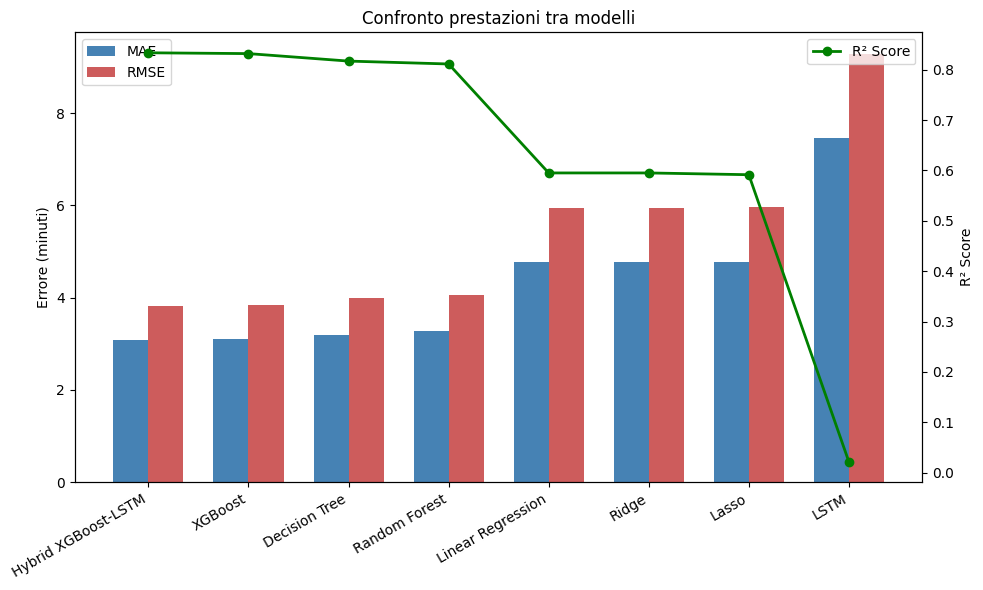

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Costruiamo una tabella riassuntiva da 'results'
summary_df = pd.DataFrame([
    {'Model': r['model'], 'MAE': r['MAE'], 'RMSE': r['RMSE'], 'R2': r['R2']}
    for r in results.values()
])
summary_df = summary_df.sort_values('R2', ascending=False).reset_index(drop=True)
print(summary_df)

# Grafico a barre + linea
fig, ax1 = plt.subplots(figsize=(10, 6))

x = range(len(summary_df))
width = 0.35

ax1.bar([i - width/2 for i in x], summary_df['MAE'], width, label='MAE', color='steelblue')
ax1.bar([i + width/2 for i in x], summary_df['RMSE'], width, label='RMSE', color='indianred')
ax1.set_ylabel('Errore (minuti)')
ax1.set_xticks(list(x))
ax1.set_xticklabels(summary_df['Model'], rotation=30, ha='right')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(x, summary_df['R2'], color='green', marker='o', linewidth=2, label='R² Score')
ax2.set_ylabel('R² Score')
ax2.legend(loc='upper right')

plt.title('Confronto prestazioni tra modelli')
plt.tight_layout()
plt.savefig('fig_comparative_performance.png', dpi=150)
plt.show()

##Predicted vs Actual per i modelli principali

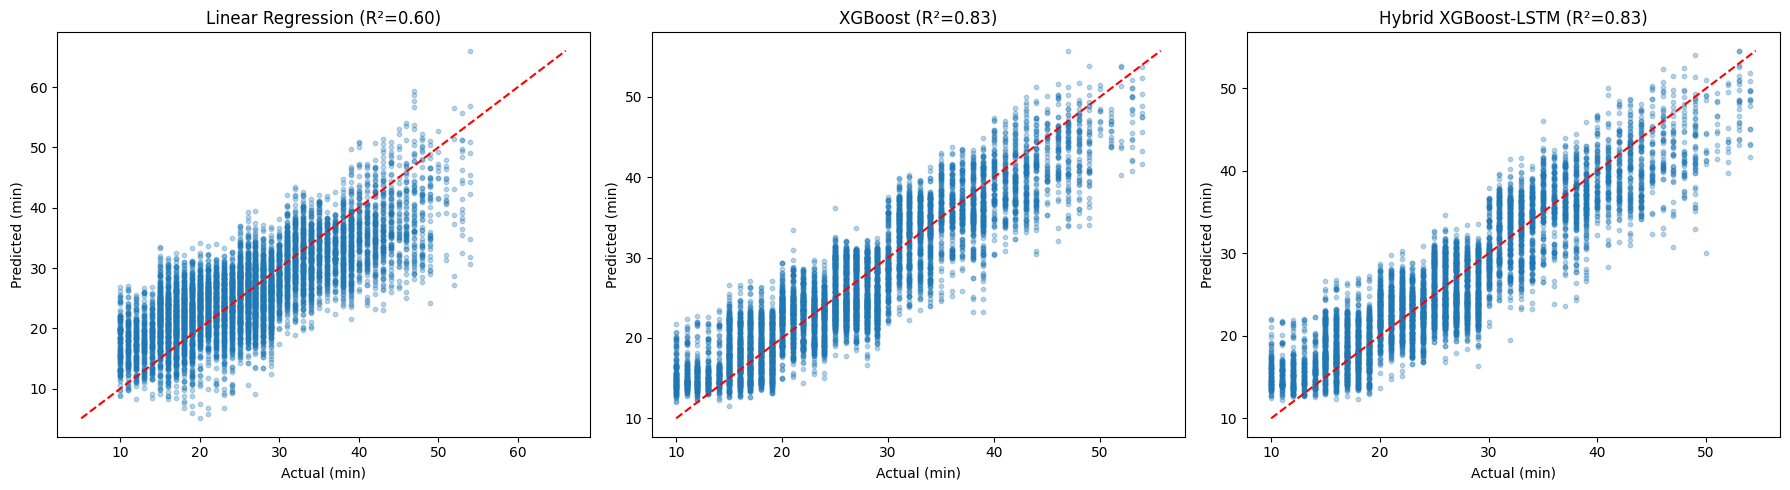

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models_to_plot = ['Linear Regression', 'XGBoost', 'Hybrid XGBoost-LSTM']

for ax, name in zip(axes, models_to_plot):
    r = results[name]
    if name == 'Hybrid XGBoost-LSTM':
        y_true = y_seq_test
    else:
        y_true = y_test
    ax.scatter(y_true, r['preds'], alpha=0.3, s=10)
    lims = [min(y_true.min(), r['preds'].min()), max(y_true.max(), r['preds'].max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5)
    ax.set_xlabel('Actual (min)')
    ax.set_ylabel('Predicted (min)')
    ax.set_title(f"{name} (R²={r['R2']:.2f})")

plt.tight_layout()
plt.savefig('fig_predicted_vs_actual.png', dpi=150)
plt.show()

##Curva di training della LSTM (loss/val_loss per epoca)

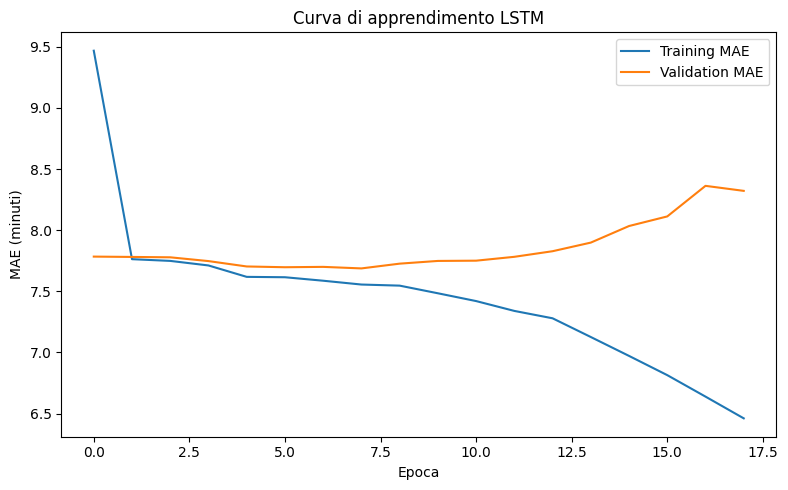

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training MAE')
plt.plot(history.history['val_loss'], label='Validation MAE')
plt.xlabel('Epoca')
plt.ylabel('MAE (minuti)')
plt.title('Curva di apprendimento LSTM')
plt.legend()
plt.tight_layout()
plt.savefig('fig_lstm_training_curve.png', dpi=150)
plt.show()

##Distribuzione del target

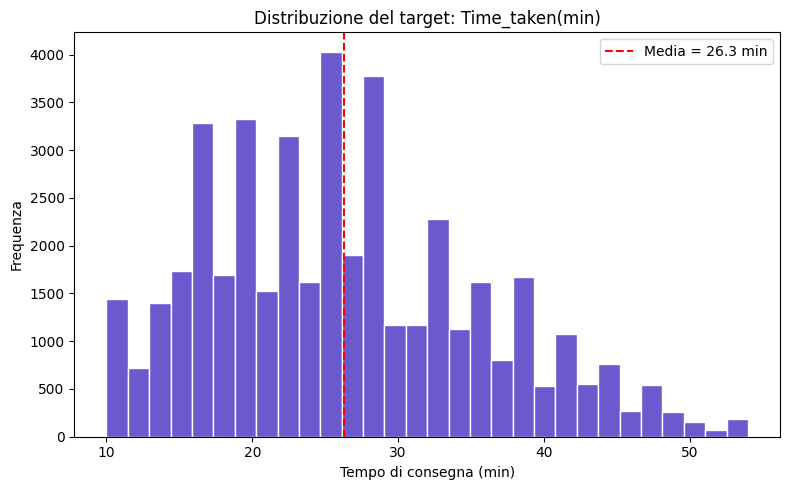

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df['Time_taken(min)'], bins=30, color='slateblue', edgecolor='white')
plt.axvline(df['Time_taken(min)'].mean(), color='red', linestyle='--', label=f"Media = {df['Time_taken(min)'].mean():.1f} min")
plt.xlabel('Tempo di consegna (min)')
plt.ylabel('Frequenza')
plt.title('Distribuzione del target: Time_taken(min)')
plt.legend()
plt.tight_layout()
plt.savefig('fig_target_distribution.png', dpi=150)
plt.show()

In [ ]:
from google.colab import files
import zipfile

with zipfile.ZipFile('grafici_relazione.zip', 'w') as zipf:
    for fname in ['fig_comparative_performance.png', 'fig_predicted_vs_actual.png',
                  'fig_lstm_training_curve.png', 'fig_target_distribution.png']:
        zipf.write(fname)

files.download('grafici_relazione.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>